# DBSCAN
- DBSCAN (Density-Based Spatial Clustering of Applications with Noise) is a popular clustering algorithm used for data analysis and pattern recognition. It groups data points based on their density, identifying clusters of high-density regions and classifying outliers as noise. DBSCAN is effective in discovering arbitrary-shaped clusters in data and is widely used in data mining, spatial data analysis, and machine learning applications.
- DBSCAN (Density-Based Spatial Clustering of Applications with Noise) is a popular density-based clustering algorithm used for identifying clusters in datasets with complex shapes and varying densities. It works by grouping points that are closely packed together based on two important parameters: epsilon (ε) and min_samples.

### Geometric Intuition:
- **Core Points:** Points that have at least min_samples points within a distance of epsilon are considered core points. They are at the heart of clusters.
- **Border Points:** Points that are within the neighborhood of a core point but don't have enough neighbors to be considered core points themselves.
Noise/Outlier Points: Points that are neither core nor border points.


### How DBSCAN Works:
- **Parameter Setup:** Set epsilon (ε) and min_samples.
- **Core Point Identification:** For each point in the dataset, identify if it's a core point by checking if it has at least min_samples points within a distance of epsilon.
- **Cluster Expansion:** Form clusters by connecting core points to their neighboring core points. Assign border points to their corresponding clusters.
Noise/Outlier Identification: Label points that are not part of any cluster as noise or outliers.

# Blog Link
- [DBSCAN](https://www.analyticsvidhya.com/blog/2020/09/how-dbscan-clustering-works/)

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math
# Initiating KMeans Clustering
from sklearn.cluster import KMeans
from sklearn.cluster import DBSCAN
from sklearn.datasets import make_moons
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

In [ ]:
np.random.seed(42)

# Function for creating datapoints in the form of a circle
def PointsInCircum(r,n=100):
    return [(math.cos(2*math.pi/n*x)*r+np.random.normal(-30,30),math.sin(2*math.pi/n*x)*r+np.random.normal(-30,30)) for x in range(1,n+1)]

In [ ]:
# Creating data points in the form of a circle
circle_points = PointsInCircum(500, 1000) + PointsInCircum(300, 700) + PointsInCircum(100, 300)

# Adding noise to the dataset
noise_points = [(np.random.randint(-600, 600), np.random.randint(-600, 600)) for _ in range(300)]

# Combining circle points and noise points into a single list
all_points = circle_points + noise_points

# Creating DataFrame from the combined points
df = pd.DataFrame(all_points, columns=['x', 'y'])


In [ ]:
df

,x,y
0,484.891555,-31.006357
1,489.391178,21.973916
2,462.886575,-27.599889
3,517.218479,5.588090
4,455.669049,1.982181
...,...,...
2295,-229.000000,-504.000000
2296,392.000000,-580.000000
2297,134.000000,525.000000
2298,469.000000,-535.000000


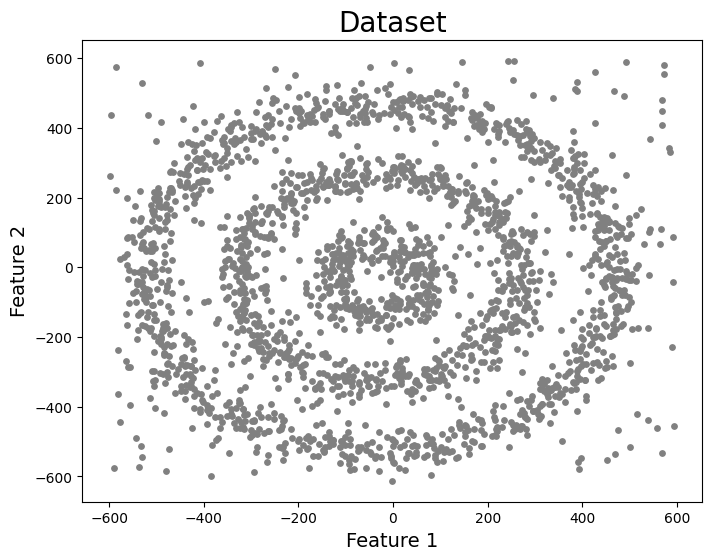

In [ ]:
plt.figure(figsize=(8,6))
plt.scatter(df["x"],df["y"],s=15,color='grey')
plt.title('Dataset',fontsize=20)
plt.xlabel('Feature 1',fontsize=14)
plt.ylabel('Feature 2',fontsize=14)
plt.show()

In [ ]:
kmeans = KMeans(n_clusters=3)

# fitting algo on my data
kmeans.fit(df)

# extracting labels
kmean_labels = kmeans.labels_

In [ ]:
# adding labels to dataframe
df["kmean_labels"] = kmean_labels

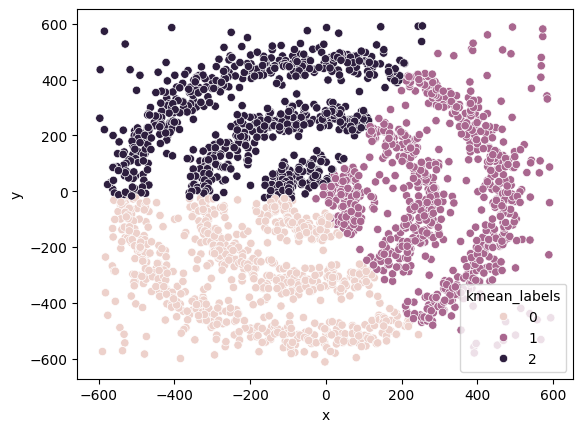

In [ ]:
sns.scatterplot(x=df["x"],y=df["y"],data=df,hue="kmean_labels")
plt.show()

In [ ]:
# applying the dbscan
dbscan=DBSCAN(eps=0.5,min_samples=5)
dbscan.fit(df[["x","y"]])

dbscan_labels = dbscan.labels_

In [ ]:
# adding dbscan labels in my data
df["dbscan labels"] = dbscan_labels

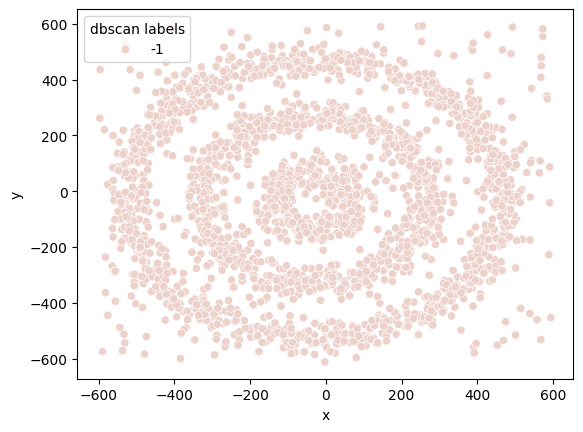

In [ ]:
sns.scatterplot(x=df["x"],y=df["y"],data=df,hue="dbscan labels")
plt.show()

In [ ]:
# applying the dbscan
dbscan=DBSCAN(eps=30,min_samples=6)
dbscan.fit(df[["x","y"]])

dbscan_labels2 = dbscan.labels_

In [ ]:
# adding dbscan labels in my data
df["dbscan labels2"] = dbscan_labels2

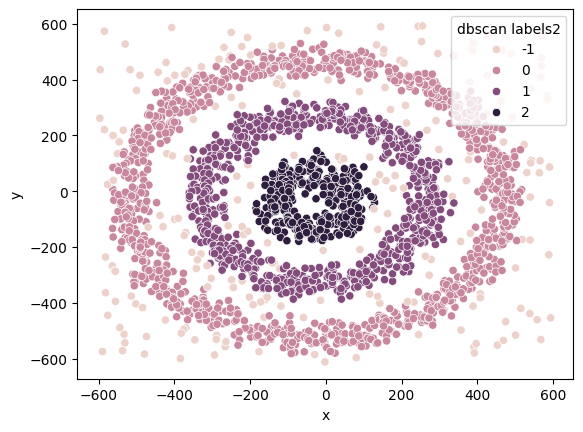

In [ ]:
sns.scatterplot(x=df["x"],y=df["y"],data=df,hue="dbscan labels2")
plt.show()

# Example 2

In [ ]:
# Generating a sample dataset (replace this with your data)
X, _ = make_moons(n_samples=300, noise=0.1)

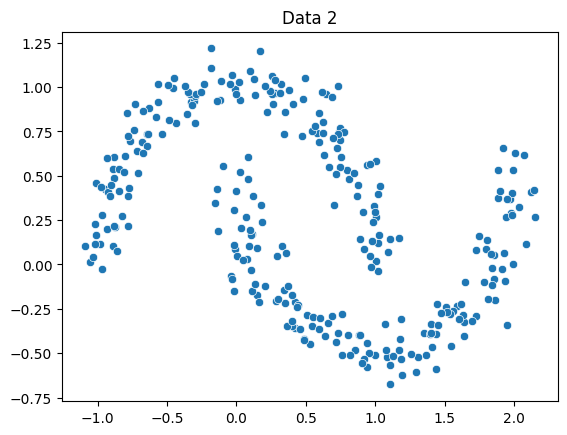

In [ ]:
sns.scatterplot(x=X[:,0],y=X[:,1])
plt.title("Data 2")
plt.show()

In [ ]:
# changing X into dataframe
df2 = pd.DataFrame(X,columns=["x","y"])

In [ ]:
# kmeans
kmeans = KMeans(n_clusters=2)

# fitting on data
kmeans.fit(df2)

# fetching the labels
kmeans_labels = kmeans.labels_

In [ ]:
# adding labels to the dataframe
df2["kmeans labels"] = kmeans_labels

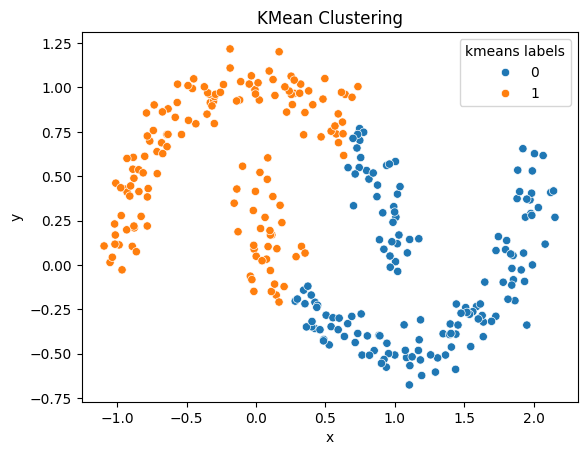

In [ ]:
sns.scatterplot(x="x",y="y",data=df2,hue="kmeans labels")
plt.title("KMean Clustering")
plt.show()

In [ ]:
# applying the dbscan
dbscan=DBSCAN(eps=0.2,min_samples=5)
dbscan.fit(df2[["x","y"]])

dbscan_labels = dbscan.labels_

In [ ]:
# adding dbscan labels in my data
df2["dbscan labels"] = dbscan_labels

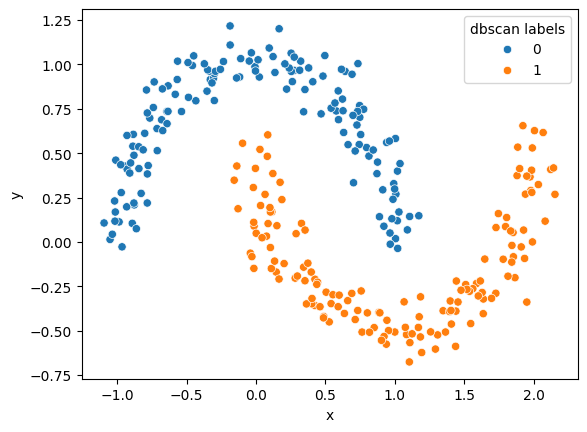

In [ ]:
sns.scatterplot(x="x",y="y",data=df2,hue="dbscan labels")
plt.show()